---
title: "L5-08 · Bell correlations and the CHSH test"
short_title: "Bell correlations and the CHSH test"
subtitle: "Every model in which outcomes depend only on local settings and a shared cause chosen independently of the settings obeys $|S| \\le 2$; entangled qubits reach $2\\sqrt{2}$ without allowing any signal, so a careful violation rules out that whole class of causal explanations."
description: "Compute a CHSH value for local and quantum strategies, prove the local bound and Tsirelson's bound, and state exactly which assumptions a violation tests."
tags: [level-5, coursebook]
---

(lesson-l5-08)=

:::{div}
:class: qcai-meta
![Level 5 icon](../../_static/icons/qicon-level-5.svg) **Level 5 · Advanced undergraduate** · about 120 minutes  
**Big idea.** Every model in which outcomes depend only on local settings and a shared cause chosen independently of the settings obeys $|S| \le 2$; entangled qubits reach $2\sqrt{2}$ without allowing any signal, so a careful violation rules out that whole class of causal explanations.  
**Before this lesson.** [L4-02](#lesson-l4-02), [L5-04](#lesson-l5-04), [L5-07](#lesson-l5-07)  
**Lab.** [Entanglement and Bell tests](../../labs/06-entanglement-bell.ipynb)
:::

## What you will be able to do

- Compute $S = E_{00} + E_{01} + E_{10} - E_{11}$ for any deterministic or stochastic local strategy and for a two-qubit state with given measurement angles.
- Prove the CHSH bound $|S| \le 2$ for local hidden-variable models, pointing to where locality (factorization) and measurement independence are used.
- Derive $E(a,b) = \cos 2(a - b)$ for $|\Phi^+\rangle$, find angles that give $S = 2\sqrt{2}$, and prove Tsirelson's bound $|S| \le 2\sqrt{2}$.
- Explain the locality, measurement-independence and detection (fair-sampling) loopholes and what the 2015 loophole-free experiments did and did not establish.

## Why this matters

Two sealed laboratories receive particles from a common source. In each round, each laboratory picks one of two settings at random and records $+1$ or $-1$. Nothing travels between the laboratories during a round. Correlations between their records are no mystery by themselves: two envelopes can share a hidden note. The question John Bell asked is sharper: is there **any** shared hidden note, however complicated, that reproduces the correlations quantum theory predicts for every combination of settings? [@bell]

The answer is a number. Clauser, Horne, Shimony and Holt combined four correlations into one quantity $S$ and showed that every model with a shared cause and local responses keeps $|S| \le 2$ [@chsh]. Entangled qubits give $S = 2\sqrt{2}$. Experiments since the 1970s have found violations, and in 2015 a test closed the two main loopholes at once [@hensen]. This lesson proves both bounds, computes the quantum strategy, and is precise about what a violation does and does not rule out. That precision matters for causal reasoning: a Bell test is the cleanest example of data that no classical causal model with the given structure can explain [@woodspekkens].

:::{dropdown} Key terms

**Correlator**
: $E_{xy} = \sum_{a,b} ab\,p(a,b|x,y)$, the average product of the two $\pm 1$ outcomes when the settings are $x$ and $y$.

**CHSH value**
: $S = E_{00} + E_{01} + E_{10} - E_{11}$, the combination used throughout this lesson.

**Local hidden-variable model**
: A model $p(a,b|x,y) = \sum_\lambda p(\lambda)\,p(a|x,\lambda)\,p(b|y,\lambda)$: a shared cause $\lambda$, chosen independently of the settings, and outcomes that depend only on the local setting and $\lambda$.

**Tsirelson's bound**
: The largest CHSH value quantum theory allows, $2\sqrt{2} \approx 2.828$.

**No signaling**
: Each party's outcome distribution does not depend on the other party's setting: $\sum_b p(a,b|x,y)$ is the same for every $y$.

**Loophole**
: A gap between the assumptions of the theorem and the conditions of an experiment, through which a local model could still mimic a violation.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l5_08 as _lessonfigs

## The CHSH scenario

Alice chooses a setting $x \in \{0, 1\}$ and obtains an outcome $a \in \{+1, -1\}$; Bob chooses $y \in \{0, 1\}$ and obtains $b \in \{+1, -1\}$. Repeating many rounds estimates the four conditional distributions $p(a, b \mid x, y)$. The settings play the role of interventions in [L4-01](#lesson-l4-01): they are chosen by the experimenters, not observed passively. The causal structure of the experiment is a DAG of the kind studied in [L4-02](#lesson-l4-02), drawn below.

:::{prf:definition} Correlators and the CHSH value
:label: def-l5-08-chsh
For settings $x, y$ the **correlator** is $E_{xy} = \sum_{a,b = \pm 1} ab\;p(a, b \mid x, y) = p(a = b \mid x, y) - p(a \ne b \mid x, y)$. The **CHSH value** is the combination in [](#eq-l5-08-chsh).
:::

$$
S = E_{00} + E_{01} + E_{10} - E_{11}
$$ (eq-l5-08-chsh)

:::{important} Conventions used in this lesson
The minus sign sits on $E_{11}$. Other choices (moving the minus sign, relabeling outcomes) give equivalent inequalities. Angles are **polarizer angles**: a setting $\theta$ means the observable $A(\theta) = \cos 2\theta\,Z + \sin 2\theta\,X$, which is how a polarizer at angle $\theta$ acts on a photon's polarization qubit ($|0\rangle$ horizontal, $|1\rangle$ vertical). For spin-$\tfrac12$ analyzers the physical angle equals the Bloch angle $2\theta$. The shared state is $|\Phi^+\rangle = (|00\rangle + |11\rangle)/\sqrt2$. The correlation explorer of [L5-04](#lesson-l5-04) and the helper `qcai.science.chsh_value` instead label the direction $\cos t\,Z + \sin t\,X$ by its Bloch angle $t = 2\theta$.
:::

The CHSH value has a game reading. Write outcomes as bits, $a = (-1)^{\alpha}$ and $b = (-1)^{\beta}$, pick $x, y$ uniformly, and say the players win when $\alpha \oplus \beta = x\,y$: agree unless both settings are 1, disagree when both are 1. The winning probability for settings $x, y$ is $(1 \pm E_{xy})/2$ with the sign of $E_{xy}$ in [](#eq-l5-08-chsh), so averaging over the four setting pairs gives

$$
p_{\rm win} = \frac12 + \frac{S}{8}
$$ (eq-l5-08-game)

## Local models obey |S| ≤ 2

:::{prf:assumption} Local hidden-variable model
:label: asm-l5-08-lhv
There is a variable $\lambda$ (discrete or continuous; sums below may be integrals) with distribution $p(\lambda)$ such that (1) **measurement independence**: $p(\lambda \mid x, y) = p(\lambda)$, the settings are chosen independently of $\lambda$; and (2) **local causality (factorization)**: $p(a, b \mid x, y, \lambda) = p(a \mid x, \lambda)\,p(b \mid y, \lambda)$, so Alice's outcome depends only on her setting and $\lambda$, and likewise for Bob. Together, $p(a, b \mid x, y) = \sum_\lambda p(\lambda)\,p(a \mid x, \lambda)\,p(b \mid y, \lambda)$.
:::

```{mermaid}
graph TD
  L(("λ shared cause")) --> A["Alice outcome a"]
  L --> B["Bob outcome b"]
  X["setting x"] --> A
  Y["setting y"] --> B
  X -.->|"forbidden: locality"| B
  Y -.->|"forbidden: locality"| A
  L -.->|"forbidden: independence"| X
```

*The causal structure behind the CHSH bound. Solid arrows are allowed. A dotted arrow from a setting to the far outcome would break locality; an arrow from $\lambda$ to a setting would break measurement independence. A violation shows that no model with only the solid arrows reproduces the data. Models that add a dotted arrow can, but only with fine-tuned parameters that hide the extra arrow in the observed statistics [@woodspekkens].*

:::{figure} ../../_static/animations/l5_08_local_strategies.mp4
:alt: Sixteen cards listing every choice of signs for A0, A1, B0, B1 with the resulting S of plus or minus 2, a histogram with eight strategies at each value, the factoring algebra, and a red point that moves between -2 and 2 as a mixture changes.
:width: 100%

All 16 local deterministic strategies give $S = \pm 2$, because $S = A_0(B_0 + B_1) + A_1(B_0 - B_1)$ has one bracket equal to 0 and the other equal to $\pm 2$. Mixtures stay in between: $|S| \le 2$.
:::

:::{dropdown} What the animation shows
The scene writes $S = E_{00} + E_{01} + E_{10} - E_{11}$ and then fills a grid of 16 cards, one per deterministic strategy $(A_0, A_1 \mid B_0, B_1)$ with each entry $\pm 1$. For a deterministic strategy $E_{xy} = A_xB_y$. Each card shows its value of $S$: eight cards show $+2$ and eight show $-2$, and a histogram on the right confirms that every value lies inside the band $|S| \le 2$. The algebra then rewrites $S = A_0B_0 + A_0B_1 + A_1B_0 - A_1B_1$ as $S = A_0(B_0 + B_1) + A_1(B_0 - B_1)$: if $B_0 = B_1$ the first bracket is $\pm 2$ and the second is 0, and if $B_0 = -B_1$ the reverse, so $S = \pm 2$ for every strategy. Finally a number line shows a mixture $S_{\rm local} = \sum_\lambda p(\lambda) S_\lambda$ with $p(\lambda)$ independent of the settings: a red point moves between the endpoints $-2$ and $+2$ as the weight of the $+2$ strategies changes, and never leaves the interval.
:::

:::{prf:theorem} CHSH inequality
:label: thm-l5-08-chsh
Every local hidden-variable model in the sense of [](#asm-l5-08-lhv) satisfies $|S| \le 2$.
:::

:::{prf:proof}
*Deterministic case.* If every outcome is a fixed function of the local setting and $\lambda$, write $A_x, B_y \in \{\pm 1\}$. Then $E_{xy} = A_xB_y$ and $S = A_0(B_0 + B_1) + A_1(B_0 - B_1)$. Since $B_0, B_1 = \pm 1$, one of $B_0 \pm B_1$ is 0 and the other is $\pm 2$, so $S = \pm 2$.

*General case.* Let $\bar A_x(\lambda) = \sum_a a\,p(a \mid x, \lambda) \in [-1, 1]$ and $\bar B_y(\lambda) = \sum_b b\,p(b \mid y, \lambda) \in [-1, 1]$. **Factorization** gives $\sum_{a,b} ab\,p(a \mid x, \lambda)p(b \mid y, \lambda) = \bar A_x(\lambda)\bar B_y(\lambda)$, and **measurement independence** lets all four correlators use the same weights $p(\lambda)$: $E_{xy} = \sum_\lambda p(\lambda)\,\bar A_x(\lambda)\bar B_y(\lambda)$. Hence $S = \sum_\lambda p(\lambda)\,s(\lambda)$ with $s = \bar A_0(\bar B_0 + \bar B_1) + \bar A_1(\bar B_0 - \bar B_1)$, and $|s| \le |\bar B_0 + \bar B_1| + |\bar B_0 - \bar B_1| = 2\max(|\bar B_0|, |\bar B_1|) \le 2$. Averaging, $|S| \le \sum_\lambda p(\lambda)|s(\lambda)| \le 2$ [@chsh; @bell].
:::

:::{prf:remark} Why both assumptions are needed
Drop measurement independence and let $\lambda$ carry the settings, $\lambda = (x, y)$; then the 'outcomes' can be chosen to win the CHSH game every round, giving $S = 4$. Drop factorization and let Bob's outcome depend on $x$; the same perfect score follows. The bound is a statement about a causal structure, not about quantum mechanics.
:::

## The quantum strategy reaches 2√2

Measure $A(a)$ on Alice's qubit and $A(b)$ on Bob's qubit of $|\Phi^+\rangle$. Expanding $A(a) \otimes A(b)$ and using $\langle\Phi^+|Z \otimes Z|\Phi^+\rangle = \langle\Phi^+|X \otimes X|\Phi^+\rangle = 1$ and $\langle\Phi^+|Z \otimes X|\Phi^+\rangle = \langle\Phi^+|X \otimes Z|\Phi^+\rangle = 0$,

$$
E(a,b) = \cos 2a\cos 2b + \sin 2a\sin 2b, \quad\text{so}\quad E(a,b) = \cos 2(a - b)
$$ (eq-l5-08-corr)

Now choose the one-parameter family $a_0 = 0$, $a_1 = 2\varphi$, $b_0 = \varphi$, $b_1 = -\varphi$. The four angle differences are $-\varphi, \varphi, \varphi, 3\varphi$, so by [](#eq-l5-08-corr)

$$
S(\varphi) = 3\cos 2\varphi - \cos 6\varphi
$$ (eq-l5-08-family)

At $\varphi = 0$ all four settings coincide and $S = 2$, exactly the local bound. Setting the derivative $-6\sin 2\varphi + 6\sin 6\varphi$ to zero gives $\varphi = 22.5^\circ$, the polarizer angles $0^\circ, 45^\circ, 22.5^\circ, -22.5^\circ$. There $E_{00} = E_{01} = E_{10} = \cos 45^\circ = 1/\sqrt2$ and $E_{11} = \cos 135^\circ = -1/\sqrt2$, so $S = 4/\sqrt2 = 2\sqrt{2} \approx 2.828$ and, by [](#eq-l5-08-game), $p_{\rm win} = \tfrac12 + \tfrac{\sqrt2}{4} = \cos^2(\pi/8) \approx 0.854$, against $3/4$ for any local strategy.

:::{figure} ../../_static/animations/l5_08_quantum_angles.mp4
:alt: A polarizer dial with Alice's two directions and Bob's two directions opening up as phi grows, next to a live trace of S against phi that rises above the local bound 2 to 2.828 at 22.5 degrees and swings down to -2.828 at 67.5 degrees.
:width: 100%

As the settings open up, $S(\varphi) = 3\cos 2\varphi - \cos 6\varphi$ climbs from 2 to $2\sqrt{2}$ at $\varphi = 22.5^\circ$: the four correlations $\pm 1/\sqrt2$ all push in the direction that helps $S$.
:::

:::{dropdown} What the animation shows
The scene states the setup: the state $|\Phi^+\rangle$, the observables $A(\theta) = \cos 2\theta\,Z + \sin 2\theta\,X$, and the correlation $E(a,b) = \cos 2(a - b)$. On the left, a polarizer dial shows four lines through its center: $a_0 = 0$, $a_1 = 2\varphi$, $b_0 = \varphi$ and $b_1 = -\varphi$. On the right, axes show $\varphi$ from 0 to 90 degrees and $S$ from $-3$ to 3, with dashed lines at the local bound $\pm 2$ and solid lines at $\pm 2\sqrt{2}$. As $\varphi$ grows from 0, the dial opens and a red point traces $S(\varphi) = 3\cos 2\varphi - \cos 6\varphi$ with its live value, starting at $+2.000$. At $\varphi = 22.5^\circ$ the scene pauses and writes $E_{00} = E_{01} = E_{10} = 1/\sqrt2$, $E_{11} = -1/\sqrt2$, and $S = 4/\sqrt2 = 2\sqrt{2} \approx 2.828$. The sweep continues to 90 degrees; the trace falls through zero at 45 degrees, reaches $-2.828$ at 67.5 degrees, and ends at $-2$. A closing note says that the sign of $S$ is a labeling choice.
:::


In [2]:
_show(_lessonfigs.chsh_explorer())

**Explore.** Drag $\varphi$ to open the settings and pick a visibility $v$ for the noisy state $v|\Phi^+\rangle\langle\Phi^+| + (1 - v)I/4$. Below $v = 1/\sqrt2 \approx 0.707$ no angle in this family beats the local bound.

:::{dropdown} What the figure shows
The first panel shows the unit circle with Alice's two polarizer directions $a_0 = 0$ and $a_1 = 2\varphi$ as solid lines and Bob's $b_0 = \varphi$, $b_1 = -\varphi$ as dashed lines. The second panel plots $S(\varphi) = v(3\cos 2\varphi - \cos 6\varphi)$ for the chosen visibility, with horizontal lines at the local bound $\pm 2$ and at Tsirelson's bound $\pm 2\sqrt{2}$, and a marker labeled with the value of $S$ at the slider's angle. The slider runs from 0 to 90 degrees in steps of 7.5 degrees and starts at 22.5 degrees. The menu offers $v = 1, 0.85, 0.75, 0.70$; the maximum $2\sqrt{2}\,v$ is $2.828, 2.404, 2.121$ and $1.980$.
:::

:::{prf:proposition} Quantum correlations do not signal
:label: prop-l5-08-nosignal
For any state $\rho_{AB}$ and any local measurements, Alice's marginal $p(a \mid x, y) = \sum_b p(a, b \mid x, y)$ does not depend on $y$. For $|\Phi^+\rangle$ every marginal is $1/2$.
:::

:::{prf:proof}
With effects $E^x_a$ for Alice and $F^y_b$ for Bob, $\sum_b p(a, b \mid x, y) = \sum_b \operatorname{Tr}[\rho_{AB}(E^x_a \otimes F^y_b)] = \operatorname{Tr}[\rho_{AB}(E^x_a \otimes I)] = \operatorname{Tr}(\rho_A E^x_a)$, because $\sum_b F^y_b = I$. The right side contains no $y$. For $|\Phi^+\rangle$, $\rho_A = I/2$ and $\operatorname{Tr}(\tfrac12 E^x_a) = \tfrac12$ for the two projectors $(I \pm A(\theta))/2$.
:::

## Tsirelson's bound

:::{prf:theorem} Tsirelson's bound
:label: thm-l5-08-tsirelson
Let $\rho$ be a state on $\mathcal H_A \otimes \mathcal H_B$ (finite-dimensional), and let $A_0, A_1$ on $\mathcal H_A$ and $B_0, B_1$ on $\mathcal H_B$ be Hermitian with $A_x^2 = B_y^2 = I$ (observables with outcomes $\pm 1$). For the CHSH operator $S = A_0 \otimes (B_0 + B_1) + A_1 \otimes (B_0 - B_1)$, $\;|\operatorname{Tr}(\rho S)| \le 2\sqrt{2}$.
:::

:::{prf:proof}
*Sum of squares.* Since $A_x \otimes I$ commutes with $I \otimes B_y$, and $A_x^2 = I$, $(B_0 \pm B_1)^2 = 2I \pm \{B_0, B_1\}$, expanding the squares gives

$$2\sqrt{2}\,I - S = \tfrac{1}{\sqrt2}\Big[\big(A_0 \otimes I - I \otimes \tfrac{B_0 + B_1}{\sqrt2}\big)^2 + \big(A_1 \otimes I - I \otimes \tfrac{B_0 - B_1}{\sqrt2}\big)^2\Big].$$

Each square of a Hermitian operator is positive semidefinite, so $\operatorname{Tr}(\rho S) \le 2\sqrt2$; applying the same identity to $-S$ (replace $B_y$ by $-B_y$) gives the lower bound. *Second route.* Squaring directly gives $S^2 = 4\,I - [A_0, A_1] \otimes [B_0, B_1]$; since $\|[A_0, A_1]\| \le 2\|A_0\|\|A_1\| = 2$, $\|S^2\| \le 8$, so $|\operatorname{Tr}(\rho S)| \le \|S\| \le 2\sqrt2$. If Alice's two observables commute, as in a classical model, $S^2 = 4I$ and the bound drops to 2 [@tsirelson1980; @preskill; @nielsenchuang].
:::

:::{figure} ../../_static/animations/l5_08_tsirelson.mp4
:alt: A derivation that squares the CHSH operator to get 4I minus a tensor product of commutators, bounds its norm by 8, then shows the sum-of-squares certificate and the Pauli observables that reach 2 sqrt 2.
:width: 100%

The identity $S^2 = 4\,I - [A_0, A_1] \otimes [B_0, B_1]$ explains everything at once: commuting observables give $|S| \le 2$, and the largest possible commutators give $2\sqrt{2}$.
:::

:::{dropdown} What the animation shows
The scene lists the hypotheses $A_x^2 = B_y^2 = I$ and that Alice's operators commute with Bob's. It writes $S = A_0 \otimes (B_0 + B_1) + A_1 \otimes (B_0 - B_1)$, recalls $(B_0 \pm B_1)^2 = 2I \pm \{B_0, B_1\}$, and transforms the expression into the boxed identity $S^2 = 4\,I - [A_0, A_1] \otimes [B_0, B_1]$. Below it, the norm bound $\|[A_0, A_1]\| \le 2\|A_0\|\|A_1\| = 2$ gives $\|S^2\| \le 4 + 2 \cdot 2 = 8$, hence $\langle S\rangle \le \|S\| \le 2\sqrt{2}$; a note says that commuting $A$'s, as in a classical model, give $S^2 = 4I$ and $|S| \le 2$. The second part writes the sum-of-squares certificate $2\sqrt2\,I - S = \frac{1}{\sqrt2}[(A_0 - \frac{B_0 + B_1}{\sqrt2})^2 + (A_1 - \frac{B_0 - B_1}{\sqrt2})^2] \ge 0$, then the optimal choice $A_0 = Z$, $A_1 = X$, $B_{0,1} = (Z \pm X)/\sqrt2$, which are the polarizer angles 0, 45, 22.5 and $-22.5$ degrees. With $[Z, X] = 2iY$ and $[B_0, B_1] = -2iY$ the identity becomes $S^2 = 4I - 4\,Y \otimes Y$, and since $Y \otimes Y|\Phi^+\rangle = -|\Phi^+\rangle$, $S^2|\Phi^+\rangle = 8|\Phi^+\rangle$.
:::

:::{prf:remark} No signaling alone allows S = 4
The Popescu-Rohrlich box [@popescu1994], $p(a, b \mid x, y) = 1/2$ whenever $\alpha \oplus \beta = xy$ (and 0 otherwise), has uniform marginals, so it cannot signal, yet it wins the CHSH game every time: $S = 4$. Tsirelson's bound is therefore a genuine feature of quantum theory, not a consequence of relativity. The figure in the next section shows the three nested ranges.
:::

:::{prf:remark} General measurements
The theorem is stated for $\pm 1$-valued projective observables. A two-outcome POVM gives an observable $A = E_+ - E_-$ with $\|A\| \le 1$; by Naimark's dilation ([L5-07](#lesson-l5-07)) it is a $\pm 1$ observable on a larger space, so the same bound $2\sqrt{2}$ holds.
:::

## From inequality to experiment: assumptions and loopholes

The theorem constrains models; an experiment estimates probabilities from finitely many detected events. Three gaps must be closed before a measured $S > 2$ refutes local hidden variables.

:::{warning} Three loopholes
1. **Locality.** The setting choice on one side and the outcome on the other must be spacelike separated, so that no signal at light speed could carry $x$ to Bob's detector before his outcome is fixed. Otherwise factorization is an untested assumption.
2. **Measurement independence (freedom of choice).** Settings must be chosen by processes plausibly independent of $\lambda$, typically fast random number generators. This can be made more plausible but never proved; models that violate it (superdeterministic models) are not excluded by any Bell test.
3. **Detection (fair sampling).** If many rounds give no detection and only detected pairs are analyzed, a local model can choose which rounds are detected and fake a violation. One must either detect efficiently enough or assume that the detected pairs are a fair sample. Fair sampling is an assumption about the experiment, not a hypothesis of the CHSH theorem.
:::

Aspect, Grangier and Roger measured polarization correlations of photon pairs from a calcium cascade with two-channel polarizers, optical analogs of Stern-Gerlach filters, and reported results in excellent agreement with quantum predictions and the largest violation of Bell inequalities achieved up to then [@aspect1982]. Like other experiments of that period, it left the locality and detection loopholes open: the analyzer settings were not switched while the photons were in flight, and only a small fraction of pairs was detected, so the analysis relied on fair sampling. In 2015 Hensen and colleagues entangled electron spins in two diamond samples 1.3 km apart and chose settings with fast random number generators; efficient spin readout removed the fair-sampling assumption and the separation enforced the locality conditions. In 245 trials they found $S = 2.42 \pm 0.20$, and a null-hypothesis test gave $p = 0.039$ for a local model to produce a violation at least that large, allowing for memory effects [@hensen]. Photonic experiments the same year reached the same conclusion with much larger data sets [@giustina2015; @shalm2015]. The 2022 Nobel Prize in Physics went to Alain Aspect, John Clauser and Anton Zeilinger for experiments with entangled photons that established the violation of Bell inequalities [@nobel2022].


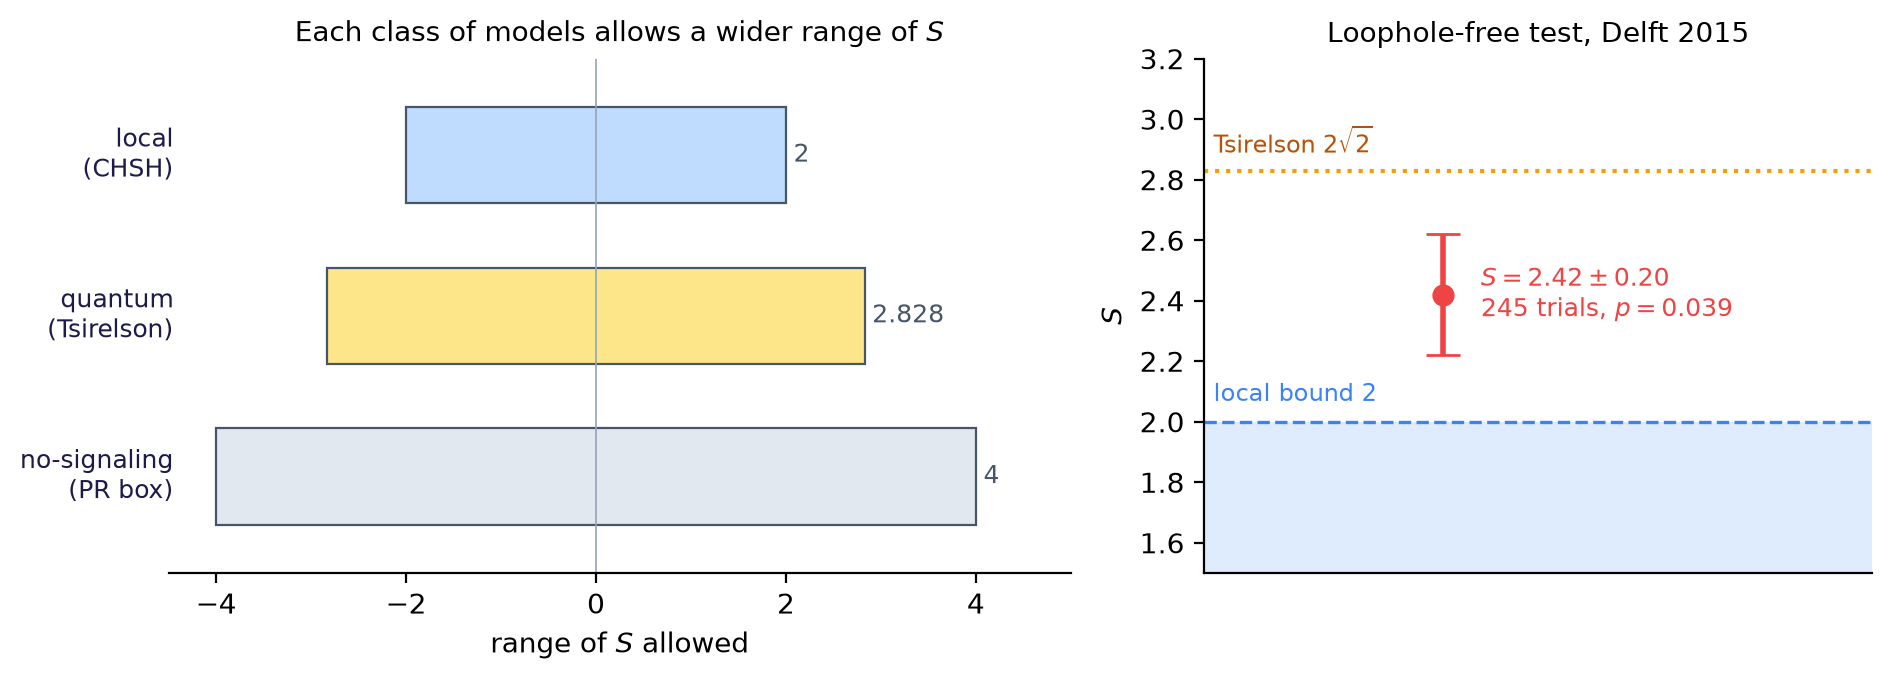

In [3]:
_show_mpl(_lessonfigs.bounds_and_experiment())

*Left: local models allow $|S| \le 2$, quantum theory $|S| \le 2\sqrt{2}$, and no-signaling alone (the PR box) $|S| \le 4$. Right: the loophole-free Delft result $S = 2.42 \pm 0.20$ from 245 trials, with $p = 0.039$ reported by the authors [@hensen]; the error bar is their stated uncertainty.*

:::{caution} What a violation does and does not show
A violation, with the loopholes closed, excludes every model satisfying [](#asm-l5-08-lhv). It does not allow faster-than-light signaling ([](#prop-l5-08-nosignal)). It does not single out one interpretation: models with nonlocal influences, models that give up measurement independence, and retrocausal models can reproduce the data, at the price of fine-tuning their causal parameters [@woodspekkens]. And it is a statistical conclusion: a point estimate above 2 without a stated test and sample size is not evidence.
:::

## Compute it

Enumerate the 16 deterministic strategies, then compute the quantum value with `qcai.science.chsh_value` (which takes Bloch angles, so polarizer angles are doubled) and directly from the matrices.


In [4]:
import itertools
import math
import numpy as np
from qcai import science as qs

def S_of(E):                      # the CHSH form of this lesson: E00 + E01 + E10 - E11
    return E[0][0] + E[0][1] + E[1][0] - E[1][1]

values = []
for A0, A1, B0, B1 in itertools.product([1, -1], repeat=4):
    values.append(S_of([[A0 * B0, A0 * B1], [A1 * B0, A1 * B1]]))
print('S over the 16 local deterministic strategies:', sorted(set(values)),
      ' counts:', {v: values.count(v) for v in sorted(set(values))})

# Quantum: |Phi+>, polarizer angles a0 = 0, a1 = 45, b0 = 22.5, b1 = -22.5 degrees.
# qcai.science.chsh_value uses Bloch angles t in cos(t) Z + sin(t) X, so t = 2 * (polarizer angle).
rho = qs.dm(qs.bell_state('phi+'))
pol = [0.0, 45.0, 22.5, -22.5]
S_q = qs.chsh_value(rho, *[2 * math.radians(d) for d in pol])
print('quantum S at these angles:', round(S_q, 6), '  2*sqrt(2) =', round(2 * math.sqrt(2), 6))

# The same correlations from the matrices: E(a, b) = <Phi+| A(a) (x) A(b) |Phi+>
Z = np.diag([1.0, -1.0])
X = np.array([[0.0, 1.0], [1.0, 0.0]])
A = lambda d: math.cos(2 * math.radians(d)) * Z + math.sin(2 * math.radians(d)) * X
psi = qs.bell_state('phi+')
E = lambda a, b: float(np.real(psi.conj() @ np.kron(A(a), A(b)) @ psi))
for a, b in [(0, 22.5), (0, -22.5), (45, 22.5), (45, -22.5)]:
    print(f'E({a:>4}, {b:>5}) = {E(a, b):+.4f}    cos 2(a - b) = {math.cos(2 * math.radians(a - b)):+.4f}')

S over the 16 local deterministic strategies: [-2, 2]  counts: {-2: 8, 2: 8}
quantum S at these angles: 2.828427   2*sqrt(2) = 2.828427
E(   0,  22.5) = +0.7071    cos 2(a - b) = +0.7071
E(   0, -22.5) = +0.7071    cos 2(a - b) = +0.7071
E(  45,  22.5) = +0.7071    cos 2(a - b) = +0.7071
E(  45, -22.5) = -0.7071    cos 2(a - b) = -0.7071


Scan the angle family, add white noise, compute game probabilities, check no signaling, and search random $\pm 1$ observables for a counterexample to Tsirelson's bound (there is none).


In [5]:
# The angle family a0 = 0, a1 = 2 phi, b0 = phi, b1 = -phi
phis = np.linspace(0, 90, 361)
S_phi = [E(0, p) + E(0, -p) + E(2 * p, p) - E(2 * p, -p) for p in phis]
k = int(np.argmax(S_phi))
print('max of S(phi):', round(S_phi[k], 4), 'at phi =', phis[k], 'degrees')
print('matches 3 cos 2phi - cos 6phi:', np.allclose(S_phi, 3 * np.cos(np.radians(2 * phis)) - np.cos(np.radians(6 * phis))))

# White noise: Werner state v |Phi+><Phi+| + (1 - v) I/4 at the optimal angles
for v in (1.0, 0.85, 0.75, 0.70):
    print(f'visibility {v:.2f}: S = {qs.chsh_value(qs.werner(v), 0, math.pi / 2, math.pi / 4, -math.pi / 4):.4f}')

print('CHSH game win probability: local', 0.5 + 2 / 8, '  quantum', round(0.5 + 2 * math.sqrt(2) / 8, 4),
      '  cos^2(pi/8) =', round(math.cos(math.pi / 8) ** 2, 4))

# No signaling: Alice's marginal does not depend on Bob's setting
def joint(a, b, sa, sb):
    Pa, Pb = (np.eye(2) + sa * A(a)) / 2, (np.eye(2) + sb * A(b)) / 2
    return float(np.real(psi.conj() @ np.kron(Pa, Pb) @ psi))
for b in (22.5, -22.5):
    print(f"Bob's setting {b:+}: p(Alice gets +1 at a0) = {joint(0, b, 1, 1) + joint(0, b, 1, -1):.4f}")

# Tsirelson: random +-1 observables on two qubits never give an eigenvalue of S above 2 sqrt 2
rng = np.random.default_rng(0)
def rand_obs():
    M = rng.normal(size=(2, 2)) + 1j * rng.normal(size=(2, 2))
    w, U = np.linalg.eigh(M + M.conj().T)
    return U @ np.diag(np.sign(w)) @ U.conj().T
best = 0.0
for _ in range(3000):
    A0, A1, B0, B1 = (rand_obs() for _ in range(4))
    S_op = np.kron(A0, B0 + B1) + np.kron(A1, B0 - B1)
    best = max(best, float(np.max(np.abs(np.linalg.eigvalsh(S_op)))))
print('largest |eigenvalue| of the CHSH operator in 3000 random trials:', round(best, 4), '(bound 2.8284)')

max of S(phi): 2.8284 at phi = 22.5 degrees
matches 3 cos 2phi - cos 6phi: True
visibility 1.00: S = 2.8284
visibility 0.85: S = 2.4042
visibility 0.75: S = 2.1213
visibility 0.70: S = 1.9799
CHSH game win probability: local 0.75   quantum 0.8536   cos^2(pi/8) = 0.8536
Bob's setting +22.5: p(Alice gets +1 at a0) = 0.5000
Bob's setting -22.5: p(Alice gets +1 at a0) = 0.5000


largest |eigenvalue| of the CHSH operator in 3000 random trials: 2.8283 (bound 2.8284)


How large is the statistical uncertainty of an estimated $S$? A seeded simulation with 1000 rounds per setting pair.


In [6]:
# Finite samples: a seeded simulation of N rounds per setting pair (not an experiment)
rng = np.random.default_rng(2022)
N = 1000
settings = [(0, 22.5), (0, -22.5), (45, 22.5), (45, -22.5)]
signs = [1, 1, 1, -1]
S_hat, var = 0.0, 0.0
for (a, b), s in zip(settings, signs):
    e = E(a, b)
    products = rng.choice([1, -1], size=N, p=[(1 + e) / 2, (1 - e) / 2])
    S_hat += s * products.mean()
    var += products.var(ddof=1) / N
print(f'estimated S = {S_hat:.3f}, one standard error = {math.sqrt(var):.3f} ({N} rounds per setting pair)')
print('The standard error is a rough guide; a real test needs a pre-registered statistic and a valid p-value.')

estimated S = 2.850, one standard error = 0.044 (1000 rounds per setting pair)
The standard error is a rough guide; a real test needs a pre-registered statistic and a valid p-value.


:::{prf:remark} Reading the output
The deterministic strategies give only $\pm 2$ (eight each). The quantum value is $2.828427$, the four correlations are $\pm 0.7071$, and the family maximum sits at $\varphi = 22.5^\circ$. With visibility $0.70$ the value $1.980$ no longer violates the bound, even though the state is still entangled (a Werner state is entangled for $v > 1/3$). The simulated estimate has a standard error of about $0.04$ with 1000 rounds per setting pair.
:::

## Worked example

:::{admonition} A noisy source at the optimal angles
:class: tip

A source emits $\rho = v|\Phi^+\rangle\langle\Phi^+| + (1 - v)I/4$ with $v = 0.9$. Using polarizer angles $a_0 = 0^\circ$, $a_1 = 45^\circ$, $b_0 = 22.5^\circ$, $b_1 = -22.5^\circ$, find the four correlators, $S$, the CHSH game winning probability, and the smallest $v$ that still violates the local bound.

1. White noise $I/4$ has every correlator 0 (since $\operatorname{Tr}[(A \otimes B)I/4] = \operatorname{Tr}A\operatorname{Tr}B/4 = 0$ for traceless $A, B$), so $E(a,b) = v\cos 2(a - b)$.
2. The angle differences are $-22.5^\circ$, $22.5^\circ$, $22.5^\circ$, $67.5^\circ$, so $E_{00} = E_{01} = E_{10} = 0.9\cos 45^\circ \approx 0.636$ and $E_{11} = 0.9\cos 135^\circ \approx -0.636$.
3. $S = 0.636 + 0.636 + 0.636 + 0.636 = 4 \times 0.9/\sqrt2 = 2\sqrt2 \times 0.9 \approx 2.546$.
4. $p_{\rm win} = \tfrac12 + S/8 \approx 0.5 + 0.318 = 0.818$, above the local maximum $0.75$.
5. A violation needs $2\sqrt2\,v > 2$, that is $v > 1/\sqrt2 \approx 0.707$.

**Result.** $S \approx 2.546$ and $p_{\rm win} \approx 0.818$; any visibility above $1/\sqrt2 \approx 0.707$ violates $|S| \le 2$ at these angles.
:::

## Exercises

**1. (Core)** An experiment reports correlators $E_{00} = 0.6$, $E_{01} = 0.6$, $E_{10} = 0.6$, $E_{11} = -0.6$. Compute $S$ and compare with the local bound. What else would you need before claiming a violation?

:::{dropdown} Solution
$S = 0.6 + 0.6 + 0.6 - (-0.6) = 2.4 > 2$ as a point value. To claim a violation you need the number of rounds per setting pair, a test statistic with its uncertainty (or a $p$-value under the local hypothesis), and a description of how the loopholes were handled.
:::

**2. (Core)** Show that the CHSH game winning probability is $p_{\rm win} = \tfrac12 + S/8$, and give its maximum for local strategies and for quantum strategies.

:::{dropdown} Solution
For $(x,y) \ne (1,1)$ the players win when $a = b$, with probability $(1 + E_{xy})/2$; for $(1,1)$ they win when $a \ne b$, with probability $(1 - E_{11})/2$. Averaging the four with weight $1/4$: $p_{\rm win} = \tfrac12 + \tfrac18(E_{00} + E_{01} + E_{10} - E_{11}) = \tfrac12 + S/8$. Local: $S \le 2$ gives $3/4$. Quantum: $S \le 2\sqrt2$ gives $\tfrac12 + \tfrac{\sqrt2}{4} = \cos^2(\pi/8) \approx 0.854$.
:::

**3. (Stretch)** Repeat the derivation of [](#eq-l5-08-corr) for the singlet $|\Psi^-\rangle = (|01\rangle - |10\rangle)/\sqrt2$. What is $S$ at the angles $0^\circ, 45^\circ, 22.5^\circ, -22.5^\circ$, and how can Bob relabel to reach $+2\sqrt2$?

:::{dropdown} Solution
For $|\Psi^-\rangle$, $\langle Z \otimes Z\rangle = \langle X \otimes X\rangle = -1$ and the cross terms vanish, so $E(a,b) = -\cos 2(a - b)$. Every correlator changes sign, so $S = -2\sqrt2$. If Bob reports $-b$ instead of $b$ (relabels his outcomes), every $E_{xy}$ flips sign again and $S = +2\sqrt2$; relabeling is a local operation, so it cannot change whether the local bound is violated in absolute value.
:::

**4. (Stretch)** A local model is allowed to depend on the settings through $\lambda$: $p(\lambda \mid x, y) \ne p(\lambda)$. Construct such a model with $S = 4$, and say which step of the proof of [](#thm-l5-08-chsh) fails.

:::{dropdown} Solution
Let $\lambda = (x, y)$, so $p(\lambda \mid x, y) = 1$ for the actual settings. Alice outputs $a = +1$ always; Bob outputs $b = -1$ if $\lambda = (1, 1)$ and $b = +1$ otherwise. Each outcome depends only on the local setting and $\lambda$, so factorization holds, but $E_{00} = E_{01} = E_{10} = 1$ and $E_{11} = -1$, giving $S = 4$. The failing step is writing all four correlators with the same weights $p(\lambda)$; measurement independence is what makes $S$ an average of $s(\lambda)$ values bounded by 2.
:::

**5. (Challenge)** Verify that the PR box $p(\alpha, \beta \mid x, y) = \tfrac12$ if $\alpha \oplus \beta = xy$ (else 0) is a valid no-signaling distribution with $S = 4$, and use [](#thm-l5-08-tsirelson) to show that no quantum state and measurements can produce it.

:::{dropdown} Solution
For each $(x,y)$ the two allowed outcome pairs have probability $\tfrac12$ each, so the distribution is normalized and nonnegative. Alice's marginal: for each $\alpha$ exactly one $\beta$ satisfies the parity condition, so $p(\alpha \mid x, y) = \tfrac12$ for every $y$; likewise for Bob, so it is no-signaling. The outcomes always agree for $(x,y) \ne (1,1)$, giving $E_{xy} = 1$, and always disagree for $(1,1)$, giving $E_{11} = -1$, so $S = 4$. Any quantum realization has outcome observables $A_x = E^x_+ - E^x_-$ and $B_y$ with norm at most 1, which by Naimark dilation can be taken to be $\pm 1$ observables on larger spaces; Tsirelson's bound then gives $S \le 2\sqrt2 < 4$, a contradiction.
:::

**6. (Challenge)** Show that $S^2 = 4\,I - [A_0, A_1] \otimes [B_0, B_1]$ for $\pm 1$ observables on separate tensor factors, and use it to show that $|\langle S\rangle| \le 2$ whenever $[A_0, A_1] = 0$, for every state.

:::{dropdown} Solution
$S = A_0 \otimes P + A_1 \otimes M$ with $P = B_0 + B_1$, $M = B_0 - B_1$. Then $S^2 = A_0^2 \otimes P^2 + A_1^2 \otimes M^2 + A_0A_1 \otimes PM + A_1A_0 \otimes MP$. Using $A_x^2 = I$, $P^2 + M^2 = 2B_0^2 + 2B_1^2 = 4I$, $PM = B_0^2 - B_0B_1 + B_1B_0 - B_1^2 = -[B_0, B_1]$ and $MP = [B_0, B_1]$, we get $S^2 = 4I - A_0A_1 \otimes [B_0, B_1] + A_1A_0 \otimes [B_0, B_1] = 4I - [A_0, A_1] \otimes [B_0, B_1]$. If $[A_0, A_1] = 0$ then $S^2 = 4I$, so the Hermitian operator $S$ has eigenvalues $\pm 2$ and $|\langle S\rangle| \le 2$ for every state, even an entangled one.
:::

## Check your understanding

**1. Does a CHSH violation let one laboratory send a faster-than-light message to the other?**

- **A.** Only when S equals 2 sqrt 2
- **B.** Yes, whenever S exceeds 2
- **C.** Only for pure entangled states
- **D.** No: each local marginal is independent of the remote setting

:::{dropdown} Show the answer
**D. No: each local marginal is independent of the remote setting**

Quantum correlations obey no signaling: $\sum_b p(a, b \mid x, y) = \operatorname{Tr}(\rho_A E^x_a)$ does not depend on $y$. A violation excludes local hidden-variable models; it does not create a communication channel.
:::

**2. What is the largest $|S|$ any local deterministic strategy can reach in the form $S = E_{00} + E_{01} + E_{10} - E_{11}$?**

- **A.** $2\sqrt{2}$
- **B.** 4
- **C.** 2
- **D.** 1

:::{dropdown} Show the answer
**C. 2**

$S = A_0(B_0 + B_1) + A_1(B_0 - B_1)$ with all values $\pm 1$: one bracket is 0 and the other is $\pm 2$, so every deterministic strategy gives exactly $\pm 2$.
:::

**3. An experiment detects only 20 percent of the pairs and analyzes the detected ones. Which extra assumption is needed to conclude against local hidden variables?**

- **A.** That the source is a pure state
- **B.** That the settings are not random
- **C.** Fair sampling of the detected pairs
- **D.** Tsirelson's bound

:::{dropdown} Show the answer
**C. Fair sampling of the detected pairs**

If most rounds give no detection, a local model can choose which rounds are detected and fake a violation. Unless detection is efficient enough, one must assume that the detected pairs are a fair sample: the detection loophole.
:::

**4. Why is $|\Phi^+\rangle = (|00\rangle + |11\rangle)/\sqrt2$ entangled?** *(Review of [L5-04](#lesson-l5-04))*

- **A.** Its two amplitudes are equal
- **B.** It cannot be written as a product $|\alpha\rangle \otimes |\beta\rangle$
- **C.** Its Z outcomes are perfectly correlated
- **D.** It is a sum of two terms

:::{dropdown} Show the answer
**B. It cannot be written as a product $|\alpha\rangle \otimes |\beta\rangle$**

A product $(\alpha_0|0\rangle + \alpha_1|1\rangle) \otimes (\beta_0|0\rangle + \beta_1|1\rangle)$ with $\alpha_0\beta_0 \ne 0$ and $\alpha_1\beta_1 \ne 0$ also has $\alpha_0\beta_1 \ne 0$, so it cannot match the zero amplitude of $|01\rangle$. Perfect Z correlation alone is also produced by the classical mixture of $|00\rangle$ and $|11\rangle$.
:::

## Common misconceptions

- **"A Bell violation proves that something travels faster than light."** Quantum predictions satisfy no signaling, and the violation rules out a class of causal models, not relativity. Nothing controllable is transmitted.
- **"Bell tests rule out every hidden-variable theory."** They rule out models with measurement independence and local factorization. Models with explicit nonlocal influences, with settings correlated with $\lambda$, or with retrocausal influences are not excluded, though they need fine-tuning to hide those influences [@woodspekkens].
- **"Every entangled state violates the CHSH inequality."** The Werner state $v|\Phi^+\rangle\langle\Phi^+| + (1 - v)I/4$ is entangled for $v > 1/3$ but gives at most $S = 2\sqrt2\,v$, which does not exceed 2 for $v \le 1/\sqrt2$. Werner showed more: some entangled states of this family admit a local hidden-variable model for every projective measurement [@werner1989]. Entanglement is necessary for a violation, not sufficient.
- **"An estimate of S above 2 is a violation."** An estimate is a random quantity. With finite data one needs a statistical test, its assumptions (for example, no memory or a method robust to it) and a $p$-value or confidence bound, as in the 2015 experiment.

:::{caution} Scope and limits
Conventions: $S = E_{00} + E_{01} + E_{10} - E_{11}$, outcomes $\pm 1$, polarizer angles with $A(\theta) = \cos 2\theta\,Z + \sin 2\theta\,X$, state $|\Phi^+\rangle$. The theorems are about ideal probabilities; the code computes exact expectation values and one seeded simulation, which is not an experiment. The experimental numbers quoted are the authors' own; this lesson does not reanalyze them. Measurement independence can never be fully closed, and the statement that a violation 'refutes local realism' is shorthand for refuting the specific assumptions listed in [](#asm-l5-08-lhv).
:::

:::{seealso} Where this leads
The CHSH scenario is the simplest causal structure in which quantum and classical predictions differ. In Level 6 it becomes the first example of a quantum causal model: the shared cause $\lambda$ is replaced by a quantum state, and the 'no fine-tuning' reading of Bell's theorem motivates the definitions of quantum common causes. Noise from [L5-06](#lesson-l5-06) lowers the visibility $v$ and with it $S$, and tomography in [L5-09](#lesson-l5-09) reconstructs the state that produces the correlations.
:::

:::{dropdown} For instructors

**Why this lesson.** The CHSH inequality is where quantum information meets causal inference: a precise causal structure, a provable bound, a quantum violation, and a sequence of experiments aimed at closing loopholes. Proving the bound with explicit assumptions trains students to read Bell claims critically [@chsh; @bell; @woodspekkens].

**Teaching notes.**

- Before any quantum mechanics, let students play the CHSH game in pairs with pre-agreed strategies; they will not beat 3/4 and the enumeration of 16 strategies explains why.
- Insist on the stated CHSH form and angle convention. Students who mix Bloch angles and polarizer angles get $E = \cos(a - b)$ and wrong optimal angles; the `qcai.science.chsh_value` call in the code makes the doubling explicit.
- Use the interactive to show that noise reduces $S$ linearly in $v$ and to locate the threshold $v = 1/\sqrt2$; then ask whether the state at $v = 0.6$ is entangled (it is) to break the 'entangled implies violation' misconception.
- Spend time on the loophole callout and the Hensen numbers: $S = 2.42 \pm 0.20$ and $p = 0.039$ are modest, and the point of that experiment was closing both loopholes at once, not the size of $S$ [@hensen].

**Assessment.** The two core exercises test computation of S and its game reading; the measurement-independence exercise and the check question on fair sampling test whether students can attach each assumption to the right step; the challenge exercises test the operator algebra behind Tsirelson's bound.

**Going further.** Read the original CHSH paper and identify where it assumes fair sampling [@chsh]. Then compare the loophole-free experiment's statistical analysis with the naive standard error computed in the last code block [@hensen]. Preskill's notes (chapter 4) discuss Bell inequalities and Tsirelson's bound in more depth [@preskill].

:::

## References

This lesson draws on [@bell; @chsh; @aspect1982; @hensen; @nobel2022; @preskill; @nielsenchuang; @woodspekkens; @tsirelson1980; @popescu1994; @giustina2015; @shalm2015; @werner1989].

**Further reading.**

- [@hensen]: The first experiment to close the locality and detection loopholes simultaneously; read its statistical analysis.
- [@woodspekkens]: A causal-discovery reading of Bell's theorem: classical explanations of the violations need fine-tuning.
- [@nielsenchuang]: Section 2.6 derives the CHSH inequality and its quantum violation.

**Next:** [L5-09 · Entropy and quantum tomography](#lesson-l5-09)
